# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

In [1]:
# VS Code setup: keep unit3_ppt3_head_ct_phantom.csv in the same folder as this notebook.
from pathlib import Path
DATA_DIR = Path.cwd()


## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

data_path = DATA_DIR / "unit3_ppt3_head_ct_phantom.csv"
if not data_path.exists():
    raise FileNotFoundError(f"Missing {data_path.name}. Put the provided CSV in the same folder as this notebook.")
ct = pd.read_csv(data_path)
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [3]:
# TODO 1  (protocol: 512 x 512 x 300 voxels, 0.5 x 0.5 x 1.0 mm, 16 bits = 2 bytes per voxel)
Nx_p, Ny_p, Nz_p = 512, 512, 300
n_voxels = Nx_p * Ny_p * Nz_p
scan_mb = n_voxels * 2 / (1024 ** 2)

# TODO 2
extent_mm = (Nx_p * 0.5, Ny_p * 0.5, Nz_p * 1.0)     # (x, y, z) in mm
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3
# front view: one ray per (x, z) pixel, rays travel along y, one sample per voxel step in y
rays_per_frame = Nx_p * Nz_p
samples_per_ray = Ny_p
samples_per_frame = rays_per_frame * samples_per_ray
samples_video = samples_per_frame * 120

# TODO 4  (early ray termination: only 35% of the samples are needed on average)
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")


78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_ In the coronal and sagittal views one of the image axes is z, and the voxels are 1.0 mm along z but only 0.5 mm in x and y. If the software treats every voxel as a square, the first thing that goes wrong is the shape: the head would look squashed in the z direction (only half as tall as it really is), so a round tumour would appear as a flat ellipse and the anatomy looks distorted. The second thing is that measurements made on those views (distances, diameters, and the volume if it is taken from pixel counts) would be wrong by a factor of 2 along z, which matters a lot for a surgeon. The fix is to use the real voxel spacing, for example by setting the aspect ratio of the two views that contain z, or by resampling the volume to isotropic voxels first (Slides 8–10).

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

1 connected component(s); largest has 431 voxels
Lesion centroid (z, y, x) = (28, 40, 41)
Without erosion: 1723 candidate voxels, 1292 of them are NOT tumour
With erosion:    431 candidate voxels, 0 of them are NOT tumour


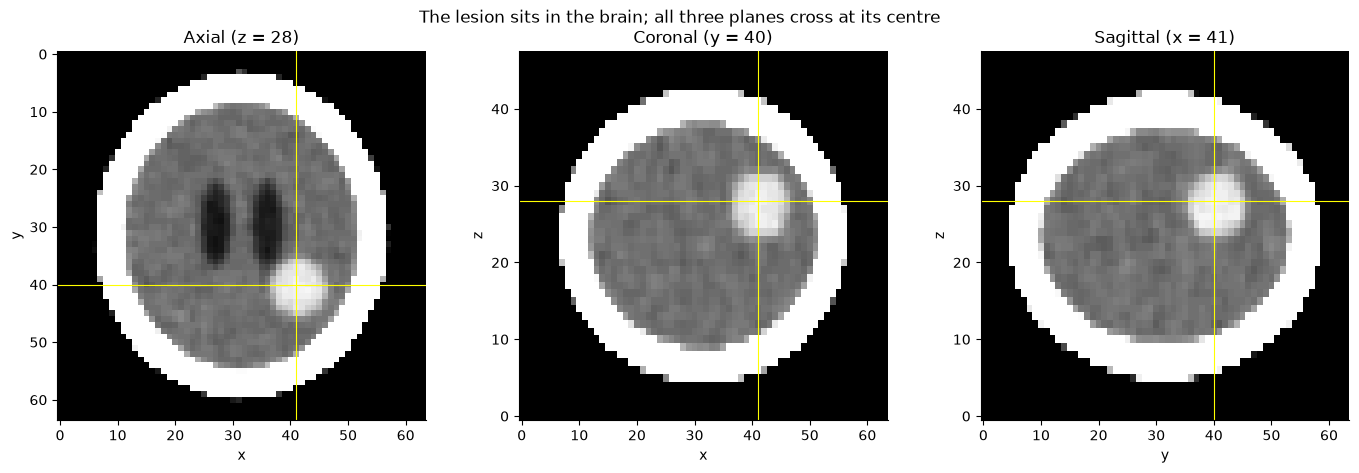

True tumour centroid (z, y, x) = (27.5, 40.5, 41.5)
My centroid is 2.9 mm away from the true centroid


In [4]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1: candidate lesion voxels (no labels used!)
skull = vol > 300                                                   # bone
inside = ndimage.binary_fill_holes(skull) & ~skull                  # everything enclosed by the skull
inside = ndimage.binary_erosion(inside, iterations=3)               # keep away from the skull edge
candidates = (vol > 55) & (vol < 90) & inside

# TODO 2: largest connected component and its centroid
comp, n_comp = ndimage.label(candidates)
sizes = ndimage.sum(candidates, comp, index=range(1, n_comp + 1))
lesion = comp == (np.argmax(sizes) + 1)
cz, cy, cx = [int(round(v)) for v in ndimage.center_of_mass(lesion)]
print(f"{n_comp} connected component(s); largest has {int(sizes.max())} voxels")
print(f"Lesion centroid (z, y, x) = ({cz}, {cy}, {cx})")

# quick check of why the erosion is needed (labels used for evaluation only)
no_erosion = (vol > 55) & (vol < 90) & ndimage.binary_fill_holes(skull) & ~skull
print(f"Without erosion: {int(no_erosion.sum())} candidate voxels, {int((no_erosion & (labels != 5)).sum())} of them are NOT tumour")
print(f"With erosion:    {int(candidates.sum())} candidate voxels, {int((candidates & (labels != 5)).sum())} of them are NOT tumour")

# TODO 3: axial / coronal / sagittal through the centroid, brain window W = 80, L = 40
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))

# axial: fixed z, shows (y, x)
axes[0].imshow(window(vol[cz, :, :], 80, 40), cmap="gray", origin="upper")
axes[0].axhline(cy, color="yellow", lw=0.8); axes[0].axvline(cx, color="yellow", lw=0.8)
axes[0].set_title(f"Axial (z = {cz})"); axes[0].set_xlabel("x"); axes[0].set_ylabel("y")

# coronal: fixed y, shows (z, x) -> z has bigger voxels so use aspect=ASPECT, head at the top
axes[1].imshow(window(vol[:, cy, :], 80, 40), cmap="gray", origin="lower", aspect=ASPECT)
axes[1].axhline(cz, color="yellow", lw=0.8); axes[1].axvline(cx, color="yellow", lw=0.8)
axes[1].set_title(f"Coronal (y = {cy})"); axes[1].set_xlabel("x"); axes[1].set_ylabel("z")

# sagittal: fixed x, shows (z, y)
axes[2].imshow(window(vol[:, :, cx], 80, 40), cmap="gray", origin="lower", aspect=ASPECT)
axes[2].axhline(cz, color="yellow", lw=0.8); axes[2].axvline(cy, color="yellow", lw=0.8)
axes[2].set_title(f"Sagittal (x = {cx})"); axes[2].set_xlabel("y"); axes[2].set_ylabel("z")

fig.suptitle("The lesion sits in the brain; all three planes cross at its centre", fontsize=12)
plt.tight_layout(); plt.show()

# TODO 4 (evaluation only): distance to the true tumour centroid
tz, ty, tx = ndimage.center_of_mass(labels == 5)
dist_mm = np.sqrt(((cz - tz) * SPACING[0]) ** 2 + ((cy - ty) * SPACING[1]) ** 2 + ((cx - tx) * SPACING[2]) ** 2)
print(f"True tumour centroid (z, y, x) = ({tz:.1f}, {ty:.1f}, {tx:.1f})")
print(f"My centroid is {dist_mm:.1f} mm away from the true centroid")


**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_ Erosion helps address the partial-volume effect. A voxel that lies on the border between the brain (about 35 HU) and the skull (400 HU and above) contains a bit of both tissues, so the scanner stores an average of them. Going across the boundary the values therefore pass through every number in between, including the 55–90 HU range that belongs to the tumour. This is the overlap of intensity ranges mentioned on Slide 28: the same HU value can come from real tumour tissue or from a blurred edge, so a threshold on HU alone cannot tell them apart. The check I added in the code shows this clearly: without erosion 1,723 voxels passed the 55–90 HU test and 1,292 of them were not tumour (they form a thin shell under the skull), while after eroding 3 times I got 431 voxels and none of them was wrong, so the largest connected component is the real lesion. Eroding removes the thin boundary layer, and a thin shell disappears while the thick tumour blob only gets a little smaller.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold_HU,voxels,volume_mL,dice
0,45,535,19.26,0.929
1,50,464,16.70,0.994
2,55,431,15.52,0.963
3,60,350,12.60,0.860
4,65,273,9.83,0.741
5,70,170,6.12,0.536


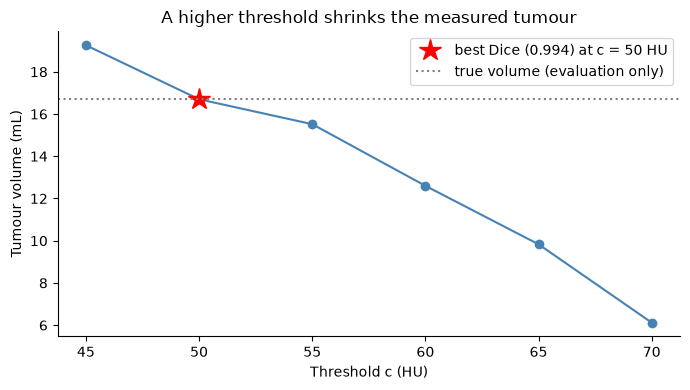

Volumes over all thresholds: 6.1 to 19.3 mL
Volume I would report (c = 50-60 HU): about 13 to 17 mL


In [5]:
truth = labels == 5
rows = []
# TODO 1 & 2
for c in [45, 50, 55, 60, 65, 70]:
    above = vol > c
    comp_c, _ = ndimage.label(above)
    seed = comp_c[cz, cy, cx]
    # region grown from the lesion centre = the connected component that contains it
    region = (comp_c == seed) if seed > 0 else np.zeros_like(above)
    n_vox = int(region.sum())
    vol_ml = n_vox * VOXEL_MM3 / 1000
    dice = 2 * (region & truth).sum() / (region.sum() + truth.sum())
    rows.append({"threshold_HU": c, "voxels": n_vox, "volume_mL": round(vol_ml, 2), "dice": round(float(dice), 3)})

table = pd.DataFrame(rows)
display(table)

# TODO 3
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table.threshold_HU, table.volume_mL, "o-", color="steelblue")
best = table.loc[table.dice.idxmax()]
ax.plot(best.threshold_HU, best.volume_mL, "r*", markersize=16, label=f"best Dice ({best.dice:.3f}) at c = {int(best.threshold_HU)} HU")
ax.axhline(truth.sum() * VOXEL_MM3 / 1000, color="gray", ls=":", label="true volume (evaluation only)")
ax.set_xlabel("Threshold c (HU)")
ax.set_ylabel("Tumour volume (mL)")
ax.set_title("A higher threshold shrinks the measured tumour")
ax.legend()
plt.tight_layout(); plt.show()

# TODO 4
print(f"Volumes over all thresholds: {table.volume_mL.min():.1f} to {table.volume_mL.max():.1f} mL")
sensible = table[table.threshold_HU.between(50, 60)]
print(f"Volume I would report (c = 50-60 HU): about {sensible.volume_mL.min():.0f} to {sensible.volume_mL.max():.0f} mL")


**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_ Without ground-truth labels, I would choose c based on the image characteristics. Inside the lesion the typical value is about 68 HU and in the normal brain around it about 35 HU, so a sensible choice is the half-way value of about 50 HU, where the edge between the two tissues actually is. In this phantom that choice gave the best Dice (0.994 at c = 50), but in real life I would justify it only by this half-way argument and by checking that the outline follows the visible edge on the slices. I would not give one number. I would report the volume as a range from the thresholds around that value (c = 50 to 60 HU gives about 13 to 17 mL), because the table shows the volume changes a lot with c (about 19 mL at 45 HU down to about 6 mL at 70 HU). To visualize the uncertainty I would draw the contours for several thresholds (for example 50, 55 and 60 HU) in different colours on the axial, coronal and sagittal slices so the surgeon can see the margin, and show the volume-vs-threshold curve with the reported range shaded on it. This way the number is seen as an estimate with an error band and not as an exact value.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

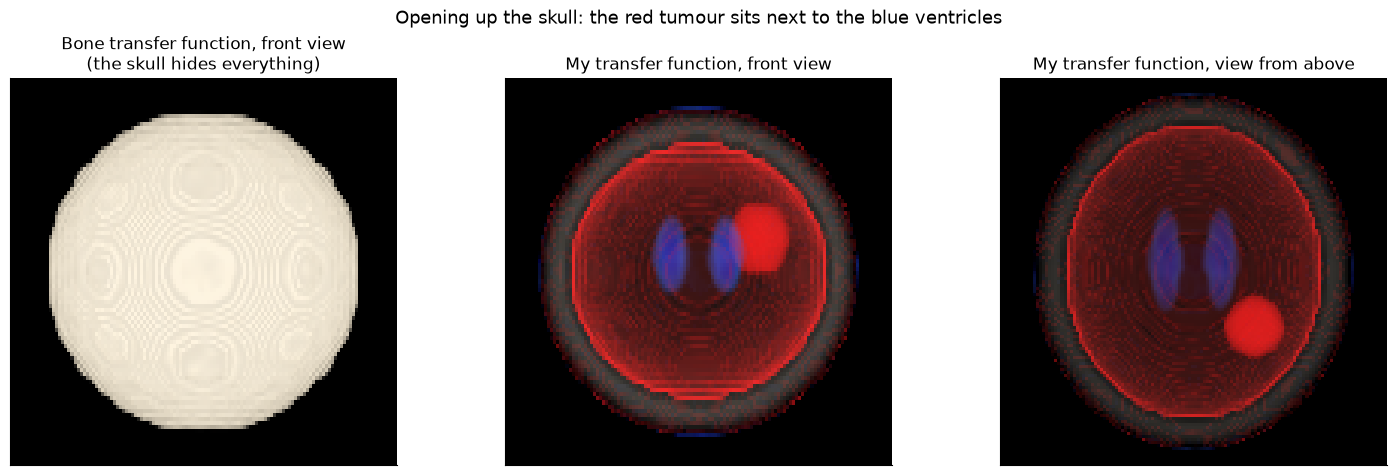

In [6]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: my transfer function
#  - air, scalp and normal brain (below ~45 HU, except CSF): fully transparent
#  - CSF (5-20 HU): faint blue
#  - tumour (about 50-80 HU): red, fairly opaque per sample so a thick blob accumulates to solid
#  - bone: nearly transparent (alpha <= 0.01) just to give a hint of the skull
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0.0),
    (0,     (0, 0, 1), 0.0),
    (4,     (0, 0, 1), 0.02),     # CSF starts
    (12,    (0.2, 0.4, 1), 0.04),
    (22,    (0.2, 0.4, 1), 0.0),  # CSF ends, normal brain (~25-45 HU) is transparent
    (45,    (1, 0, 0), 0.0),
    (52,    (1, 0.1, 0.1), 0.09), # tumour starts
    (80,    (1, 0.1, 0.1), 0.09),
    (95,    (1, 0, 0), 0.0),      # tumour ends
    (300,   (1, 1, 1), 0.0),
    (400,   (1, 0.95, 0.85), 0.004),
    (1500,  (1, 1, 1), 0.01),     # bone: almost transparent
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
# TODO 1 & 3: bone render | my TF front view | my TF top view
C_b, A_b = render(vol, bone_tf, axis=1)
axes[0].imshow(np.clip(C_b, 0, 1), origin="lower", aspect=ASPECT)
axes[0].set_title("Bone transfer function, front view\n(the skull hides everything)")

C_f, A_f = render(vol, tumour_tf, axis=1)
axes[1].imshow(np.clip(C_f, 0, 1), origin="lower", aspect=ASPECT)
axes[1].set_title("My transfer function, front view")

C_t, A_t = render(vol, tumour_tf, axis=0)
axes[2].imshow(np.clip(C_t, 0, 1))
axes[2].set_title("My transfer function, view from above")

for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
# TODO 4: suptitle
fig.suptitle("Opening up the skull: the red tumour sits next to the blue ventricles", fontsize=13)
plt.tight_layout(); plt.show()


**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_ The faint red rim comes from the issue seen in Task 2: intensity overlap combined with the partial-volume effect (Slide 28). The voxels at the boundary between the brain and the skull get averaged HU values, some of which fall in the 50–90 HU range that my transfer function paints red. Also, rays that graze the inside of the skull travel through many of these boundary voxels, so their opacity accumulates and the thin shell becomes visible as a rim. A technique that would remove it is segmentation (Slides 31–32): I could render only the voxels of the region I already grew from the lesion centre (the lesion mask), and then the boundary voxels would not be drawn at all. A transfer function alone cannot do this because it is a function of the intensity only, T(s). A boundary voxel and a real tumour voxel can have exactly the same HU, so they necessarily get the same colour and opacity. To separate them we need extra information that is not in the intensity, such as the position (a mask from segmentation) or a second property like the gradient magnitude.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_ The lesion is a round, bright mass in the brain, on the right side of the image (x ≈ 41) and towards the back (y ≈ 40) at about the middle height of the head (z ≈ 28), just beside one of the two ventricles. Its volume is about 13 to 17 mL if the threshold is set between 50 and 60 HU, but it can look anywhere from about 6 to 19 mL if the threshold is chosen badly, so the number should be read as a range and not as an exact value. I recommend opening the meeting with the three-plane MPR (axial, coronal and sagittal slices crossing at the lesion), because slicing exposes the internal structure without the occlusion that hid the tumour behind the skull in the first render, and with the correct voxel aspect ratio the anatomy and distances are not distorted. The segmentation then gives the volume and the 3-D render gives a quick overview of how the tumour sits next to the ventricles. A limitation of the 3-D render is that it depends on how the transfer function was designed: the overlap of HU ranges and partial-volume voxels create a faint false red rim under the skull, and the colours and opacities show how I set the transfer function, so the render should not be used for measuring.